# G-SOMIT hydrogen case studies with pysomit v2

This notebook reproduces the two research cases using the installable library.
It compares the manuscript's G-SOMIT results and original CRITIC convention with
CRITIC computed after cost/benefit alignment. Each manuscript-model simulation
uses 10,000 runs, log-normal comparison noise with standard deviation 0.25,
uniform multiplicative ACM noise of ±10%, and seed 42.

A separate bounded example respects percentage and rating scales. Its results
describe a different uncertainty model. The supplied inputs are the source
project's literature-informed matrices and illustrative expert profiles.

Install the package with the `examples` extra, then execute all cells. Outputs
are saved under `examples/results/` and `figures_output/` in this repository.


In [1]:
%matplotlib inline
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import Markdown, display

from pysomit import __version__, critic_weights, gsomit, monte_carlo_gsomit, somit_part2, topsis
from pysomit.datasets import load_case_study

candidates = (Path.cwd(), Path.cwd().parent)
ROOT = next((p for p in candidates if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its examples directory.")
RESULTS = ROOT / "examples" / "results"
FIGURES = ROOT / "figures_output"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "font.family": "DejaVu Sans"})

N_SIMULATIONS = 10_000
BOUNDED_SIMULATIONS = 2_000
SEED = 42
versions = {
    "python": platform.python_version(),
    "pysomit": __version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
}
print(json.dumps(versions, indent=2))

{
  "python": "3.13.5",
  "pysomit": "2.0.0",
  "numpy": "2.4.3",
  "scipy": "1.17.1",
  "pandas": "3.0.1",
  "matplotlib": "3.10.8"
}


## Deterministic results

The package loads both ACMs and all seven decision-maker profiles without
importing or executing the original research script. G-SOMIT solves each
expert's quadratic problem, aggregates the resulting weights, computes objective
weights from average absolute deviation from the median, and combines both
vectors. The following checks use the manuscript's four-decimal TOPSIS scores
and exact rank orders.


In [2]:
cases = {name: load_case_study(name) for name in ("production", "storage")}
models = {}
rankings = {}
expected_scores = {
    "production": [0.8342, 0.7371, 0.5386, 0.5109, 0.2781],
    "storage": [0.4311, 0.3106, 0.4839, 0.6887, 0.4437],
}
expected_ranks = {"production": [1, 2, 3, 4, 5], "storage": [4, 5, 2, 1, 3]}

for name, case in cases.items():
    display(Markdown(f"### {case.name}"))
    criterion_ids = [f"C{i + 1}" for i in range(len(case.criteria))]
    acm_table = pd.DataFrame(case.acm, index=case.alternatives, columns=criterion_ids)
    acm_table.index.name = "Alternative"
    display(acm_table)
    model = gsomit(case.acm, case.decision_makers)
    models[name] = model
    ranking = topsis(case.acm, model.weights, case.types)
    rankings[name] = ranking
    np.testing.assert_allclose(ranking.scores, expected_scores[name], rtol=0, atol=5e-5)
    np.testing.assert_array_equal(ranking.ranks, expected_ranks[name])
    print(f"Consensus index: {model.group.consensus_index:.8f}")
    individual = pd.DataFrame(
        model.group.individual_weights,
        index=[dm.name for dm in case.decision_makers],
        columns=criterion_ids,
    )
    display(individual.round(6))
    weight_columns = {
        "Subjective": model.group.weights,
        "Objective": model.objective_weights,
        "G-SOMIT": model.weights,
        "CRITIC preference": critic_weights(case.acm, case.types),
        "CRITIC all increasing": critic_weights(case.acm, case.types, orientation="all_increasing"),
    }
    weight_table = pd.DataFrame(weight_columns, index=criterion_ids)
    weight_table.index.name = "Criterion"
    display(weight_table.round(6))
    score_table = pd.DataFrame(index=case.alternatives)
    score_table.index.name = "Alternative"
    for method, method_weights in weight_columns.items():
        comparison = topsis(case.acm, method_weights, case.types)
        score_table[f"{method} score"] = comparison.scores
        score_table[f"{method} rank"] = comparison.ranks
    display(score_table.round(4))
    acm_table.to_csv(RESULTS / f"{name}_acm.csv")
    individual.to_csv(RESULTS / f"{name}_individual_weights.csv", float_format="%.10g")
    weight_table.to_csv(RESULTS / f"{name}_weights.csv", float_format="%.10g")
    score_table.to_csv(RESULTS / f"{name}_scores.csv", float_format="%.10g")

print("Both G-SOMIT baseline score and rank checks passed.")

### Green hydrogen production technology selection

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10
Alternative,,,,,,,,,,
AWE,850.0,4.2,65.0,9.0,1.8,10.0,25.0,99.50,2.0,5.0
PEM,1200.0,5.1,60.0,8.0,2.2,9.5,18.0,99.99,5.0,4.0
SOEC,2800.0,4.5,85.0,5.0,2.8,7.5,8.0,99.90,2.0,2.0
BG,2100.0,3.5,42.0,6.0,8.5,20.0,20.0,95.00,1.0,3.0
STWS,5500.0,7.8,25.0,3.0,0.8,6.0,12.0,99.50,1.0,1.0


Consensus index: 0.30020213


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10
DM1: Energy Policy Expert,0.184681,0.250953,0.111381,0.148031,0.038082,0.048785,0.036650,0.019757,0.013649,0.148031
DM2: Chemical Engineer,0.048565,0.147485,0.235020,0.196050,0.056356,0.026071,0.026071,0.147485,0.017977,0.098919
DM3: Environmental Scientist,0.023826,0.046308,0.136232,0.044962,0.310343,0.226157,0.091270,0.023826,0.050767,0.046308
DM4: Energy Economist,0.190587,0.260699,0.037861,0.114866,0.020213,0.013903,0.152726,0.013903,0.042515,0.152726


,Subjective,Objective,G-SOMIT,CRITIC preference,CRITIC all increasing
Criterion,,,,,
C1,0.103935,0.103027,0.104535,0.079593,0.133675
C2,0.189156,0.092696,0.171170,0.112320,0.119411
C3,0.140244,0.106036,0.145173,0.088724,0.092308
C4,0.143955,0.114979,0.161582,0.073638,0.080034
C5,0.078808,0.086607,0.066631,0.120592,0.106269
C6,0.058181,0.090340,0.051311,0.132271,0.100160
C7,0.078597,0.112724,0.086491,0.109641,0.085950
C8,0.040780,0.082797,0.032962,0.114758,0.111903
C9,0.035097,0.095815,0.032829,0.091537,0.090225


,Subjective score,Subjective rank,Objective score,Objective rank,G-SOMIT score,G-SOMIT rank,CRITIC preference score,CRITIC preference rank,CRITIC all increasing score,CRITIC all increasing rank
Alternative,,,,,,,,,,
AWE,0.8265,1.0,0.7266,2.0,0.8342,1.0,0.7224,2.0,0.7427,2.0
PEM,0.7367,2.0,0.7749,1.0,0.7371,2.0,0.7725,1.0,0.7947,1.0
SOEC,0.5664,3.0,0.5117,3.0,0.5386,3.0,0.5791,3.0,0.5713,3.0
BG,0.5033,4.0,0.4034,4.0,0.5109,4.0,0.3360,5.0,0.4119,5.0
STWS,0.3180,5.0,0.3781,5.0,0.2781,5.0,0.5061,4.0,0.4214,4.0


... (3 outputs left out)

,C1,C2,C3,C4,C5,C6,C7,C8
DM1: Safety Engineer,0.052452,0.041034,0.119798,0.039382,0.198563,0.269793,0.198563,0.080416
DM2: Process Engineer,0.150459,0.239747,0.049535,0.199994,0.150459,0.051390,0.100924,0.057492
DM3: Logistics Manager,0.097900,0.145631,0.327488,0.050169,0.047731,0.063684,0.026304,0.241093


,Subjective,Objective,G-SOMIT,CRITIC preference,CRITIC all increasing
Criterion,,,,,
C1,0.115331,0.096586,0.088904,0.109065,0.129234
C2,0.141691,0.147720,0.167048,0.139603,0.129309
C3,0.156848,0.117157,0.146658,0.102613,0.123483
C4,0.092231,0.133402,0.098197,0.140317,0.118028
C5,0.141470,0.129892,0.146658,0.125650,0.130341
C6,0.120579,0.144324,0.138890,0.159985,0.127121
C7,0.101531,0.115459,0.093559,0.123659,0.117437
C8,0.130318,0.115459,0.120086,0.099107,0.125047


,Subjective score,Subjective rank,Objective score,Objective rank,G-SOMIT score,G-SOMIT rank,CRITIC preference score,CRITIC preference rank,CRITIC all increasing score,CRITIC all increasing rank
Alternative,,,,,,,,,,
CGH2,0.4485,2.0,0.4363,4.0,0.4311,4.0,0.4266,4.0,0.4345,2.0
LH2,0.3276,5.0,0.2998,5.0,0.3106,5.0,0.2924,5.0,0.3185,5.0
MH,0.4165,4.0,0.4917,2.0,0.4839,2.0,0.4951,2.0,0.4196,4.0
NH3,0.7226,1.0,0.6572,1.0,0.6887,1.0,0.6356,1.0,0.7018,1.0
LOHC,0.4306,3.0,0.4471,3.0,0.4437,3.0,0.4486,3.0,0.4219,3.0


Both G-SOMIT baseline score and rank checks passed.


## Manuscript-model Monte Carlo analysis

Both cases use a separate local legacy NumPy random generator initialized with
seed 42. Expert identities and the chosen median/highest/lowest criteria stay
fixed. The comparison values and ACM entries are redrawn independently each run.
No physical bounds or integer restrictions are imposed in this reproduction
mode. The library checks every solution and retains every run.

The improved solver is not expected to reproduce the original unchecked SLSQP
script bit for bit. The assertions below check the previously verified top-rank
counts: AWE in 9,997 of 10,000 production runs, and NH3 in 10,000 of 10,000 storage
runs. Percentile bands describe the simulated uncertainty model.


In [3]:
def summary_frame(summary, labels):
    return pd.DataFrame(
        {
            "Mean": summary.mean,
            "Population std": summary.std,
            "Median": summary.median,
            "5th percentile": summary.lower,
            "95th percentile": summary.upper,
        },
        index=labels,
    )


simulations = {}
record = {"versions": versions, "cases": {}}
for name, case in cases.items():
    print(f"Running {N_SIMULATIONS:,} manuscript-model simulations: {name}")
    simulation = monte_carlo_gsomit(
        case.decision_makers,
        case.acm,
        case.types,
        n_simulations=N_SIMULATIONS,
        comparison_noise=0.25,
        acm_noise=0.10,
        seed=SEED,
        rng="legacy",
    )
    simulations[name] = simulation
    assert simulation.n_requested == simulation.n_completed == N_SIMULATIONS
    np.testing.assert_allclose(simulation.weight_samples.sum(axis=1), 1, atol=1e-12)
    np.testing.assert_allclose(simulation.ranking_probabilities.sum(axis=0), 1, atol=1e-12)
    np.testing.assert_allclose(simulation.ranking_probabilities.sum(axis=1), 1, atol=1e-12)
    probabilities = pd.DataFrame(
        simulation.ranking_probabilities,
        index=case.alternatives,
        columns=[f"Rank {i + 1}" for i in range(len(case.alternatives))],
    )
    probabilities.index.name = "Alternative"
    display(probabilities)
    weight_stats = summary_frame(
        simulation.weight_summary(), [f"C{i + 1}" for i in range(len(case.criteria))]
    )
    weight_stats.index.name = "Criterion"
    score_stats = summary_frame(simulation.score_summary(), case.alternatives)
    score_stats.index.name = "Alternative"
    display(weight_stats.round(6))
    display(score_stats.round(6))
    probabilities.to_csv(RESULTS / f"{name}_rank_probabilities.csv", float_format="%.10g")
    weight_stats.to_csv(RESULTS / f"{name}_weight_intervals.csv", float_format="%.10g")
    score_stats.to_csv(RESULTS / f"{name}_score_intervals.csv", float_format="%.10g")
    counts = np.sum(simulation.rank_samples == 1, axis=0).astype(int)
    record["cases"][name] = {
        "metadata": simulation.metadata,
        "alternatives": list(case.alternatives),
        "baseline_scores": rankings[name].scores.tolist(),
        "baseline_weights": models[name].weights.tolist(),
        "consensus_index": models[name].group.consensus_index,
        "first_rank_counts": counts.tolist(),
        "ranking_probabilities": simulation.ranking_probabilities.tolist(),
    }
    print(f"Completed and retained: {simulation.n_completed:,}; first-rank counts: {counts}")

if N_SIMULATIONS == 10_000 and SEED == 42:
    assert record["cases"]["production"]["first_rank_counts"] == [9997, 3, 0, 0, 0]
    assert record["cases"]["storage"]["first_rank_counts"] == [0, 0, 0, 10000, 0]
    print("Both seeded 10,000-run top-rank checks passed.")

Running 10,000 manuscript-model simulations: production


,Rank 1,Rank 2,Rank 3,Rank 4,Rank 5
Alternative,,,,,
AWE,0.9997,0.0003,0.0000,0.0000,0.0
PEM,0.0003,0.9997,0.0000,0.0000,0.0
SOEC,0.0000,0.0000,0.7862,0.2138,0.0
BG,0.0000,0.0000,0.2138,0.7862,0.0
STWS,0.0000,0.0000,0.0000,0.0000,1.0


,Mean,Population std,Median,5th percentile,95th percentile
Criterion,,,,,
C1,0.103006,0.011296,0.102430,0.085231,0.122715
C2,0.168367,0.019873,0.167485,0.137606,0.202122
C3,0.143959,0.015864,0.143377,0.118872,0.170927
C4,0.158988,0.018216,0.158595,0.129905,0.189868
C5,0.065399,0.007900,0.064902,0.053141,0.079273
C6,0.051080,0.006583,0.050706,0.041057,0.062624
C7,0.086002,0.010160,0.085417,0.070444,0.103289
C8,0.044867,0.008465,0.044241,0.032196,0.059664
C9,0.032577,0.004259,0.032415,0.025912,0.039911


,Mean,Population std,Median,5th percentile,95th percentile
Alternative,,,,,
AWE,0.832547,0.022640,0.832985,0.794590,0.868653
PEM,0.732861,0.029609,0.732960,0.683526,0.781304
SOEC,0.537617,0.025144,0.537754,0.496842,0.578790
BG,0.509958,0.024941,0.510011,0.469113,0.551614
STWS,0.276841,0.022219,0.275904,0.241743,0.314881


Completed and retained: 10,000; first-rank counts: [9997    3    0    0    0]
Running 10,000 manuscript-model simulations: storage


,Rank 1,Rank 2,Rank 3,Rank 4,Rank 5
Alternative,,,,,
CGH2,0.0,0.1600,0.2816,0.5583,0.0001
LH2,0.0,0.0000,0.0000,0.0013,0.9987
MH,0.0,0.7461,0.1473,0.1062,0.0004
NH3,1.0,0.0000,0.0000,0.0000,0.0000
LOHC,0.0,0.0939,0.5711,0.3342,0.0008


,Mean,Population std,Median,5th percentile,95th percentile
Criterion,,,,,
C1,0.089339,0.013180,0.088416,0.069028,0.112491
C2,0.166660,0.020990,0.165787,0.134131,0.202602
C3,0.145854,0.017025,0.145294,0.119136,0.175238
C4,0.098435,0.014645,0.097598,0.076124,0.123771
C5,0.147895,0.021149,0.146638,0.114757,0.184065
C6,0.135092,0.018502,0.134506,0.106099,0.167033
C7,0.092688,0.013878,0.091805,0.071575,0.116626
C8,0.124036,0.018762,0.123077,0.095433,0.156404


,Mean,Population std,Median,5th percentile,95th percentile
Alternative,,,,,
CGH2,0.433511,0.031153,0.433219,0.382146,0.484594
LH2,0.312778,0.027803,0.312348,0.267149,0.359018
MH,0.480628,0.031971,0.480423,0.428302,0.534263
NH3,0.691536,0.028868,0.691929,0.643263,0.738314
LOHC,0.441695,0.028603,0.441078,0.395772,0.489463


Completed and retained: 10,000; first-rank counts: [    0     0     0 10000     0]
Both seeded 10,000-run top-rank checks passed.


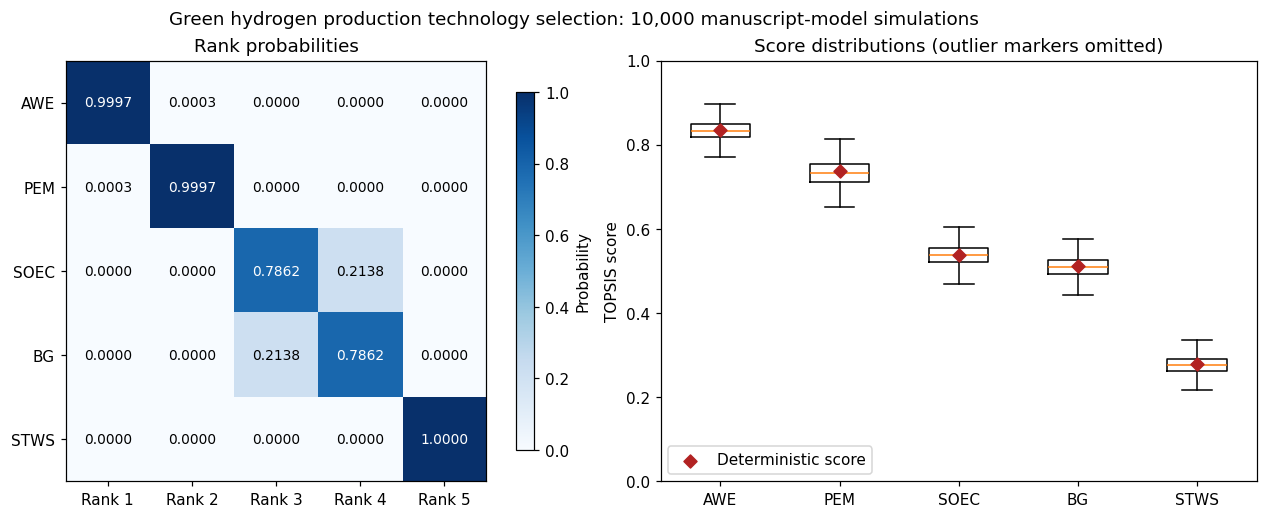

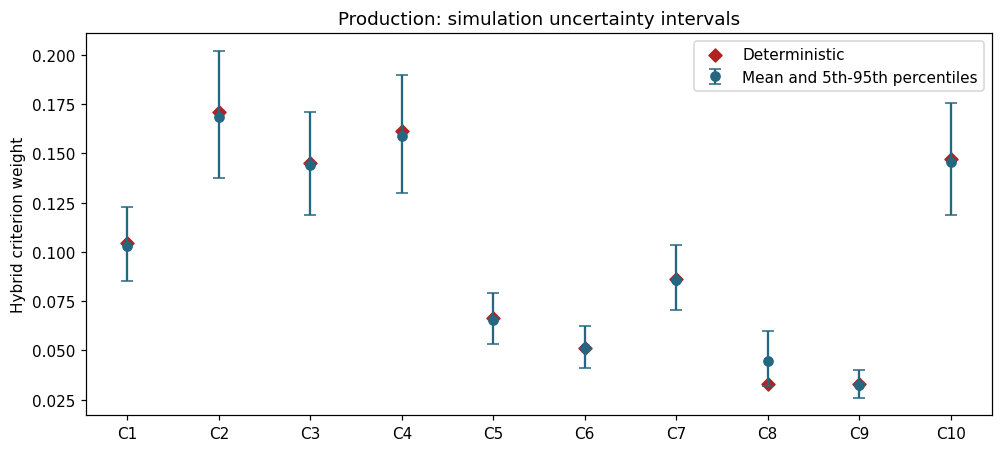

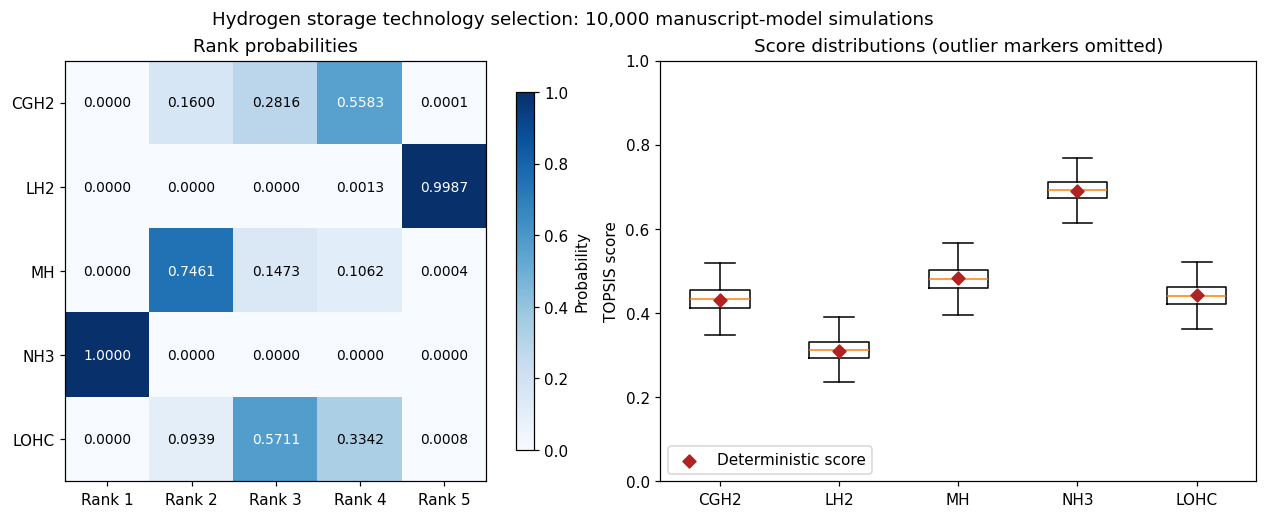

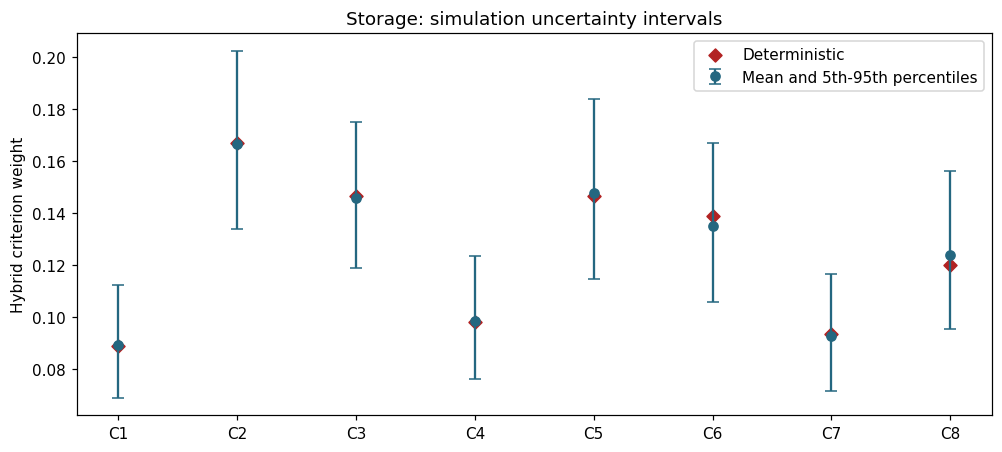

In [4]:
for name, case in cases.items():
    simulation = simulations[name]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), layout="constrained")
    probabilities = simulation.ranking_probabilities
    heatmap = axes[0].imshow(probabilities, vmin=0, vmax=1, cmap="Blues")
    axes[0].set_xticks(range(5), [f"Rank {i + 1}" for i in range(5)])
    axes[0].set_yticks(range(5), case.alternatives)
    axes[0].set_title("Rank probabilities")
    for row in range(5):
        for column in range(5):
            value = probabilities[row, column]
            axes[0].text(
                column,
                row,
                f"{value:.4f}",
                ha="center",
                va="center",
                color="white" if value > 0.55 else "black",
                fontsize=9,
            )
    fig.colorbar(heatmap, ax=axes[0], shrink=0.85, label="Probability")
    axes[1].boxplot(simulation.score_samples, showfliers=False)
    axes[1].set_xticks(range(1, 6), case.alternatives)
    axes[1].scatter(
        range(1, 6),
        rankings[name].scores,
        color="#b22222",
        marker="D",
        label="Deterministic score",
        zorder=3,
    )
    axes[1].set_ylabel("TOPSIS score")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("Score distributions (outlier markers omitted)")
    axes[1].legend(loc="lower left")
    fig.suptitle(f"{case.name}: {N_SIMULATIONS:,} manuscript-model simulations")
    fig.savefig(FIGURES / f"{name}_ranking_uncertainty.png", dpi=180)
    plt.show()
    plt.close(fig)

    summary = simulation.weight_summary()
    positions = np.arange(1, len(case.criteria) + 1)
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.errorbar(
        positions,
        summary.mean,
        yerr=[summary.mean - summary.lower, summary.upper - summary.mean],
        fmt="o",
        capsize=4,
        color="#246780",
        label="Mean and 5th-95th percentiles",
    )
    ax.scatter(positions, models[name].weights, marker="D", color="#b22222", label="Deterministic")
    ax.set_xticks(positions, [f"C{i}" for i in positions])
    ax.set_ylabel("Hybrid criterion weight")
    ax.set_title(f"{name.capitalize()}: simulation uncertainty intervals")
    ax.legend()
    fig.savefig(FIGURES / f"{name}_weight_uncertainty.png", dpi=180)
    plt.show()
    plt.close(fig)

## Optional bounded model

This example restricts percentages to [0, 100], technology readiness to [1, 9],
other ratings to [1, 5], and remaining quantities to nonnegative values. Rating
columns are discrete. The uniform intervals are truncated at the bounds;
sampling does not clip continuous draws onto the boundaries.

The same ±10% relative intervals often contain only one feasible integer for a
rating, so those ratings remain unchanged. Different per-criterion uncertainty
levels can be supplied when justified. This demonstration uses 2,000 simulations
per case and does not substitute its results into the manuscript's original
10,000-run claims.


In [5]:
bounded_records = {}
for name, case in cases.items():
    bounded = monte_carlo_gsomit(
        case.decision_makers,
        case.acm,
        case.types,
        n_simulations=BOUNDED_SIMULATIONS,
        seed=SEED,
        acm_bounds=(case.lower_bounds, case.upper_bounds),
        integer_criteria=case.integer_criteria,
    )
    table = pd.DataFrame(
        {
            "Manuscript model: rank 1": simulations[name].ranking_probabilities[:, 0],
            "Bounded model: rank 1": bounded.ranking_probabilities[:, 0],
            "Bounded mean score": bounded.score_summary().mean,
        },
        index=case.alternatives,
    )
    table.index.name = "Alternative"
    display(Markdown(f"### {name.capitalize()}"))
    display(table)
    table.to_csv(RESULTS / f"{name}_bounded_comparison.csv", float_format="%.10g")
    bounded_records[name] = {
        "metadata": bounded.metadata,
        "ranking_probabilities": bounded.ranking_probabilities.tolist(),
        "mean_scores": bounded.score_summary().mean.tolist(),
    }
record["bounded_examples"] = bounded_records

### Production

,Manuscript model: rank 1,Bounded model: rank 1,Bounded mean score
Alternative,,,
AWE,0.9997,1.0,0.832812
PEM,0.0003,0.0,0.734265
SOEC,0.0000,0.0,0.538128
BG,0.0000,0.0,0.510644
STWS,0.0000,0.0,0.276158


### Storage

,Manuscript model: rank 1,Bounded model: rank 1,Bounded mean score
Alternative,,,
CGH2,0.0,0.0,0.431784
LH2,0.0,0.0,0.311057
MH,0.0,0.0,0.482628
NH3,1.0,1.0,0.689618
LOHC,0.0,0.0,0.442023


## The source project's outlier scenario

The production scenario increases AWE's GHG emissions value from 1.8 to 18.0.
The table reports the maximum absolute change in objective weights under this
single perturbation. It includes both CRITIC direction conventions. An advantage
in this scenario is not a general proof of outlier robustness: min-max
normalization and average absolute deviations can both respond to extremes.


In [6]:
case = cases["production"]
contaminated = case.acm.copy()
contaminated[0, 4] = 18.0
outlier_rows = []
for label, method in (
    ("SOMIT Part II", somit_part2),
    ("CRITIC preference", lambda data: critic_weights(data, case.types)),
    (
        "CRITIC all increasing",
        lambda data: critic_weights(data, case.types, orientation="all_increasing"),
    ),
):
    original_weights, contaminated_weights = method(case.acm), method(contaminated)
    outlier_rows.append(
        {
            "Method": label,
            "Maximum absolute weight change": float(
                np.max(np.abs(original_weights - contaminated_weights))
            ),
        }
    )
outlier_table = pd.DataFrame(outlier_rows).set_index("Method")
display(outlier_table)
outlier_table.to_csv(RESULTS / "production_outlier_comparison.csv", float_format="%.10g")
record["outlier_comparison"] = outlier_rows
(RESULTS / "reproduction_summary.json").write_text(
    json.dumps(record, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
print("Saved all numerical summaries and four figures.")
print("G-SOMIT production scores:", np.round(rankings["production"].scores, 4))
print("G-SOMIT storage scores:", np.round(rankings["storage"].scores, 4))

,Maximum absolute weight change
Method,
SOMIT Part II,0.016257
CRITIC preference,0.045776
CRITIC all increasing,0.015585


Saved all numerical summaries and four figures.
G-SOMIT production scores: [0.8342 0.7371 0.5386 0.5109 0.2781]
G-SOMIT storage scores: [0.4311 0.3106 0.4839 0.6887 0.4437]


## Interpretation

The deterministic reproduction and seeded counts above test the manuscript's
G-SOMIT calculations. Correcting CRITIC's direction convention changes its
comparison scores and can change its ordering; the notebook keeps those outputs
explicitly labeled. Bounded sampling addresses known measurement scales but
introduces different modeling assumptions, which should be justified for each
application.

The consensus index may be negative. With two or three alternatives, SOMIT
Part II assigns equal weights to every nonconstant criterion. Its median center
does not establish universal outlier resistance. The 5th-95th percentile ranges
are simulation uncertainty intervals conditional on the selected perturbation
model, not frequentist confidence intervals.
